# Cartesian CO mocks: Li model only

Run from the extracted folder. All lengths are cMpc/h; temperatures are microK. The synthetic example is for checking the workflow, not an ASTRID prediction.


In [14]:
import numpy as np
from astropy.cosmology import Planck15
from lim_mocker_cartesian import (
    load_astrid, behroozi_sfr, li_luminosity, make_map, power_spectrum, save_map,
)

z = 2.5
h = Planck15.h
H_z = Planck15.H(z).value  # km/s/Mpc

boxsize = 250.             # cMpc/h


In [15]:
filein = '/projects/pbreysse/lya_forest_CO/lya_storage/COMAP_z2.39-3.44_1140Mpc_seed_13579.npz'
halo_info  = np.load(filein, allow_pickle=True)     
params_dict    = halo_info['cosmo_header'][()]


In [16]:
params_dict

{'h': 0.7,
 'sigma8': 0.82,
 'Omega_M': 0.286,
 'Omega_L': 0.714,
 'Omega_B': 0.047,
 'ns': 0.96}

In [17]:
params_dict    = halo_info['cosmo_header'][()]
print('redshift center', (np.max(halo_info['x']) - np.min(halo_info['x']))/2 + np.min(halo_info['x']))

redshift center -2.61083984375


In [18]:
np.max(halo_info['z'])  - np.min(halo_info['z']) 

1160.6445

In [19]:
print(np.max(halo_info['zhalo']) )

3.501330249782713


In [20]:
print(np.min(halo_info['zhalo']) )

2.3234318390207536


## 1. A small synthetic catalog
The same functions below work on the ASTRID catalog.


In [21]:
rng = np.random.default_rng(7)
N = 20_000
positions = rng.uniform(0, boxsize, (N, 3))
velocities = rng.normal(0, 150, (N, 3))  # physical peculiar km/s
mass = 10**rng.uniform(10.1, 13.5, N)   # physical Msun

# Li: halo mass -> mean SFR -> infrared luminosity -> CO luminosity.
sfr = behroozi_sfr(mass, z)
Lco = li_luminosity(sfr, sigma_sfr=.3, sigma_co=.3, seed=42)

Tco, metadata = make_map(positions, Lco, boxsize, 48, z, h, H_z,
                         velocities=velocities, los=2)
pk = power_spectrum(Tco, boxsize)
print("Map shape:", Tco.shape)
print("Mean CO temperature [microK]:", Tco.mean())
print("First k [h/cMpc]:", pk["k"][pk["nmodes"] > 0][:5])
# save_map("co_demo.npz", Tco, metadata)


[5.20833333 5.20833333 5.20833333]
Map shape: (48, 48, 48)
Mean CO temperature [microK]: 0.08805150707211412
First k [h/cMpc]: [0.03769911 0.06283185 0.08796459 0.11309734 0.13823008]


## 2. Your ASTRID run
Edit the configuration at the top of `run_astrid.py`, then enable the next cell, or run `python run_astrid.py` on the cluster. It contains the same four steps above. Set the actual Ly-alpha mesh/origin/grid offset. The reader assumes positions in ckpc/h, mass in 10^10 Msun/h, and velocities converted to physical peculiar km/s. It loads the catalog into RAM.


In [22]:
RUN_ASTRID = True
if RUN_ASTRID:
    import run_astrid
    Tco, metadata, pk = run_astrid.main()
    boxsize = metadata["boxsize_cmpch"]


1057302
249999.77
[0.25 0.25 0.25]


FileExistsError: [Errno 17] File exists: 'co_li_cartesian.npz'

## 3. Auto power and CO × Ly-alpha power
For a map already containing delta_F, do not divide by its mean again. Cross power can be negative; retain its sign. Both fields must share their box, mesh, origin, sample locations and RSD convention.


Text(0, 0.5, '$P_{CO}\\ [\\mu K^2(\\mathrm{cMpc}/h)^3]$')

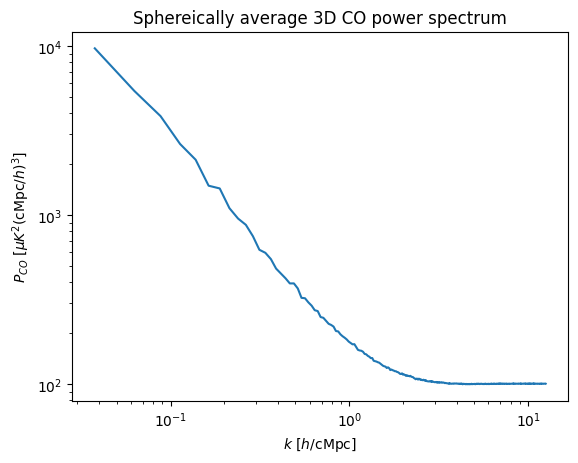

In [26]:
# Optional plot:
import matplotlib.pyplot as plt

pk = np.load('co_li_power.npz')
good = (pk["nmodes"] > 0) & (pk["Pk"] > 0)
plt.loglog(pk["k"][good], pk["Pk"][good])
plt.xlabel(r"$k\ [h/\mathrm{cMpc}]$")
plt.title("Sphereically average 3D CO power spectrum")
plt.ylabel(r"$P_{CO}\ [\mu K^2(\mathrm{cMpc}/h)^3]$")




# pk_peak = np.load('co_li_power_peak.npz')
# good = (pk_peak["nmodes"] > 0) & (pk_peak["Pk"] > 0)
# plt.loglog(pk_peak["k"][good], pk_peak["Pk"][good])
# plt.xlabel(r"$k\ [h/\mathrm{cMpc}]$")
# plt.ylabel(r"$P_{CO}\ [\mu K^2(\mathrm{cMpc}/h)^3]$")

# cross = power_spectrum(Tco, boxsize, field_b=delta_F)
# k, Pcross = cross["k"], cross["Pk"]


In [12]:
# # Optional plot:
# import matplotlib.pyplot as plt
# import numpy as np
# co_pk = np.load('co_li_power.npz')
# good = (pk["nmodes"] > 0) & (pk["Pk"] > 0)
# plt.loglog(pk["k"][good], pk["Pk"][good],label ="astrid")
# plt.xlabel(r"$k\ [h/\mathrm{cMpc}]$")
# plt.ylabel(r"$P_{CO}\ [\mu K^2(\mathrm{cMpc}/h)^3]$")




# pk_1 = np.load('co_li_power_peak.npz')
# plt.loglog(pk_1["k"], pk_1["k"]**3*pk_1["Pk"]/(2*np.pi**2),label ="peak")
# plt.xlabel(r"$k\ [h/\mathrm{cMpc}]$")
# plt.ylabel(r"$P_{CO}\ [\mu K^2(\mathrm{cMpc}/h)^3]$")
# plt.legend()
# After loading your actual aligned Ly-alpha cube:
# cross = power_spectrum(Tco, boxsize, field_b=delta_F)
# k, Pcross = cross["k"], cross["Pk"]

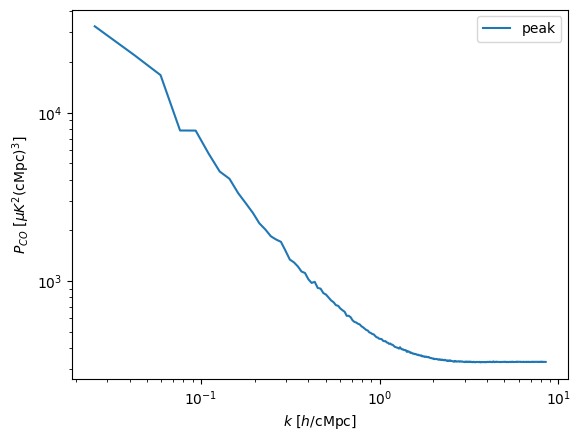

In [24]:
pk_1 = np.load('co_li_power_peak.npz')
plt.loglog(pk_1["k"]* h, pk_1["Pk"]/ h**3,label ="peak")
plt.xlabel(r"$k\ [h/\mathrm{cMpc}]$")
plt.ylabel(r"$P_{CO}\ [\mu K^2(\mathrm{cMpc})^3]$")
plt.legend()

In [ ]:
Pshot = metadata["point_source_shot_microK2_cmpch3"]
plt.axhline(Pshot, color="red", ls="--", label="Unsmoothed shot noise")

In [16]:
with np.load("/users/jiawenfan/work/lya_CO/previous_astro_cross/lila/notebooks/astrid_co_lya_cross_simplified.npz") as data:
    k_cross = data["k"]
    p_cross = data["P"]
with np.load('/users/jiawenfan/work/lya_CO/previous_astro_cross/lila/notebooks/3d_lya_parallel.npz') as data:
    k_ly = data["k"]
    p_ly = data["P"]


In [26]:
len(k_ly)

32

In [25]:
len(k_cross)

61

In [27]:
len(pk["k"][good])

30

In [18]:
min(k_ly)

0.032072956079750733

In [22]:
min(pk["k"][good])

0.03769911184307752

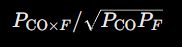

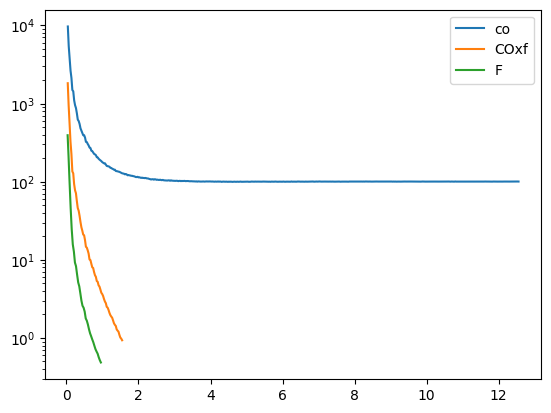

In [17]:
plt.plot(pk["k"][good], pk["Pk"][good],label = "co")
plt.plot(k_cross, p_cross,label = "COxf")
plt.plot(k_ly,p_ly,label = "F")
plt.yscale("log")
plt.legend()

## Starting from measured SFR instead
This uses the same Li SFR-to-CO conversion. Skip the Behroozi lookup and set `sigma_sfr=0`, because the catalog already supplies individual SFRs.
```python
halos = load_astrid("/your/Subhalo", h, read_sfr=True)
Lco = li_luminosity(halos["sfr"], sigma_sfr=0, sigma_co=.3, seed=42)
```
Use the same `make_map` call with the catalog positions and velocities.
